<!-- open-in-badges -->
[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_3_ajuste_supervisado.ipynb) [![Abrir en Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/EAFIT-IA/si7011-DeepLearning/blob/main/sessions/06_foundation_models/notebooks/sesion_06_3_ajuste_supervisado.ipynb) [![Abrir en Lightning Studio](https://pl-bolts-doc-images.s3.us-east-2.amazonaws.com/app-2/studio-badge.svg)](https://lightning.ai/new?repo_url=https%3A%2F%2Fgithub.com%2FEAFIT-IA%2Fsi7011-DeepLearning%2Fblob%2Fmain%2Fsessions%2F06_foundation_models%2Fnotebooks%2Fsesion_06_3_ajuste_supervisado.ipynb)

# SI7011 · Sesión 06 · 3. De modelo de lenguaje a asistente: ajuste supervisado (SFT)
**Juan David Martínez Vargas · Universidad EAFIT**

Acompaña las **Partes 3 y 5** de las diapositivas. Tomamos un modelo **base** (Qwen2.5-0.5B: preentrenado solo para predecir el token siguiente) y lo ajustamos con pares pregunta–respuesta en español, con la pérdida enmascarada y LoRA de las diapositivas. Preentrenar no cabe en una clase; ajustar sí.

| Sección | Lo que cambia | Qué mirar |
|---|---|---|
| 1 | el modelo base y su tokenizador | cuántos tokens cuesta el español |
| 2 | una plantilla de chat | qué token es plantilla, pregunta o respuesta |
| 3 | el modelo base, preguntado | ¿responde? ¿se detiene? |
| 4 | los datos: Dolly-15k en español | 2 000 pares sin contexto |
| 5 | la pérdida enmascarada, a mano | la misma que la de la librería |
| 6 | LoRA, a mano | 0.4 % de los parámetros, y el modelo intacto al empezar |
| 7 | entrenar unos minutos | NLL de validación antes y después |
| 8 | antes y después | las mismas preguntas; ¿se detiene ahora? |

**Datos:** [`argilla/databricks-dolly-15k-curated-multilingual`](https://huggingface.co/datasets/argilla/databricks-dolly-15k-curated-multilingual), split `es`: las 15 000 instrucciones de Databricks Dolly, traducidas al español con DeepL (CC BY-SA 3.0). La traducción es automática: algunas respuestas suenan raras, y el modelo las imita.

**Usa GPU** (Kaggle T4 o Colab). En Kaggle activa **Internet** en *Settings*: el modelo (1 GB) y los datos se bajan de Hugging Face. Todo el notebook tarda unos 10–15 minutos. Sin GPU corre con 48 ejemplos, solo para ver que funciona.

In [1]:
# Kaggle trae torchao 0.10, que las versiones recientes de transformers y peft rechazan al importarse
# ("Found an incompatible version of torchao"). Este notebook no lo usa: si es viejo, se desinstala.
import os
from importlib.metadata import version, PackageNotFoundError
try:
    if tuple(int(x) for x in version('torchao').split('.')[:2]) < (0, 16):
        os.system('pip uninstall -y -q torchao')
except (PackageNotFoundError, ValueError):
    pass

import json, math, os, random, time, textwrap
from collections import Counter
from contextlib import contextmanager
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
import torch.nn.functional as F

try:
    import transformers, datasets
except ImportError:                                         # Kaggle y Colab ya las traen
    os.system('pip install -q transformers datasets')
    import transformers, datasets
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

random.seed(0); torch.manual_seed(0)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '· transformers', transformers.__version__, '·', dev)
if dev == 'cpu':
    print('Sin GPU: el notebook corre con muy pocos ejemplos y tarda. En Kaggle: Settings → Accelerator → GPU T4.')

PyTorch 2.11.0+cu128 · transformers 5.16.1 · cuda


## 1. El modelo base
Un decodificador como el de la diapositiva 32: 24 bloques pre-norm con autoatención causal, entrenado con la pérdida del token siguiente sobre unos 18 billones de tokens. Es el modelo **base**, no la versión *Instruct*: nadie le enseñó a conversar. Congelamos todos sus pesos.

In [2]:
MODELO = 'Qwen/Qwen2.5-0.5B'          # el modelo BASE: solo preentrenado (token siguiente), sin SFT

def cargar_modelo(nombre=MODELO):
    tok = AutoTokenizer.from_pretrained(nombre)
    try:                                                    # transformers >= 4.56 usa dtype=
        m = AutoModelForCausalLM.from_pretrained(nombre, dtype=torch.float32)
    except TypeError:
        m = AutoModelForCausalLM.from_pretrained(nombre, torch_dtype=torch.float32)
    return tok, m.to(dev).eval()

tok, modelo = cargar_modelo()
for p in modelo.parameters():
    p.requires_grad_(False)                                 # el modelo base queda congelado
N_TOTAL = sum(p.numel() for p in modelo.parameters())
cfg = modelo.config
FIN = tok.eos_token_id
print(f'{MODELO}: {N_TOTAL / 1e6:.0f} M parámetros · {cfg.num_hidden_layers} bloques · d = {cfg.hidden_size} · '
      f'{cfg.num_attention_heads} cabezas · |V| = {len(tok):,}')
print('token de fin:', repr(tok.eos_token), FIN)

config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

Qwen/Qwen2.5-0.5B: 494 M parámetros · 24 bloques · d = 896 · 14 cabezas · |V| = 151,665
token de fin: '<|endoftext|>' 151643


Su tokenizador es BPE sobre bytes (diapositivas 38–39) con unos 151 000 tokens, entrenado sobre muchos idiomas. **Predice antes de correr:** ¿cuántos tokens necesita una frase en español frente a la misma en inglés?

In [3]:
for frase in ['Me senté en el banco del parque.', 'El ingeniero de sistemas desarrolló un algoritmo.',
              'Electroencefalografista', 'The systems engineer developed an algorithm.']:
    ids = tok.encode(frase, add_special_tokens=False)
    piezas = [tok.decode([i]) for i in ids]
    print(f'{len(frase):3d} caracteres → {len(ids):2d} tokens:  ' + ' | '.join(p.replace(' ', '·') for p in piezas))

 32 caracteres → 10 tokens:  Me | ·sent | é | ·en | ·el | ·banco | ·del | ·par | que | .
 49 caracteres → 12 tokens:  El | ·ingen | iero | ·de | ·sistemas | ·desarroll | ó | ·un | ·al | gorit | mo | .
 23 caracteres →  6 tokens:  Elect | ro | ence | fal | ograf | ista
 44 caracteres →  7 tokens:  The | ·systems | ·engineer | ·developed | ·an | ·algorithm | .


Los espacios van pegados a la palabra siguiente (`·de`). Las palabras frecuentes son un token; las raras, como *electroencefalografista*, se parten. El inglés suele necesitar menos tokens por frase que el español: el vocabulario se entrenó con más inglés, y cada token de más cuesta cómputo y contexto.

## 2. La plantilla de chat
Un par (pregunta, respuesta) se convierte en **una** secuencia (diapositiva 68):

`Usuario: <pregunta>⏎Asistente: <respuesta><|endoftext|>`

Usamos una plantilla de texto simple; los modelos *Instruct* usan marcadores especiales propios, pero la idea es la misma. Codificamos pedazo por pedazo para saber el **papel** de cada token: plantilla, pregunta o respuesta. El token de fin va **dentro** de la respuesta: es lo que le enseña al modelo a parar.

In [4]:
USUARIO, ASISTENTE = 'Usuario:', '\nAsistente:'

def codificar(instruccion, respuesta=None):
    """Ids de la plantilla, pedazo por pedazo, y el papel de cada token:
    0 = plantilla, 1 = pregunta, 2 = respuesta (con el token de fin)."""
    trozos = [(USUARIO, 0), (' ' + instruccion.strip(), 1), (ASISTENTE, 0)]
    ids, papel = [], []
    for texto, k in trozos:
        t = tok.encode(texto, add_special_tokens=False)
        ids += t; papel += [k] * len(t)
    if respuesta is not None:
        t = tok.encode(' ' + respuesta.strip(), add_special_tokens=False) + [FIN]   # aprender a PARAR
        ids += t; papel += [2] * len(t)
    return ids, papel

ids, papel = codificar('¿Qué es un átomo?', 'Partícula mínima de un elemento químico.')
print(tok.decode(ids))
print()
for k, nombre in enumerate(['plantilla', 'pregunta', 'respuesta']):
    print(f'{nombre:>10}:', ' | '.join(tok.decode([i]).replace('\n', '⏎').replace(' ', '·')
                                          for i, p in zip(ids, papel) if p == k))

Usuario: ¿Qué es un átomo?
Asistente: Partícula mínima de un elemento químico.<|endoftext|>

 plantilla: Usuario | : | ⏎ | As | ist | ente | :
  pregunta: ·¿ | Qué | ·es | ·un | ·á | t | omo | ?
 respuesta: ·Part | ícul | a | ·mín | ima | ·de | ·un | ·elemento | ·qu | ím | ico | . | <|endoftext|>


## 3. El modelo base, preguntado
**Predice** (diapositiva 47): el modelo solo aprendió a continuar texto. Con `Usuario: ¿Qué es un átomo?⏎Asistente:`, ¿responde? ¿Se detiene, o sigue escribiendo?

Generamos con greedy (diapositiva 46) y como máximo 120 tokens.

In [5]:
@torch.no_grad()
def responder(instruccion, max_nuevos=120):
    """Greedy (diapositiva 46). Devuelve el texto y si el modelo produjo el token de fin."""
    ids, _ = codificar(instruccion)
    x = torch.tensor([ids], device=dev)
    out = modelo.generate(input_ids=x, attention_mask=torch.ones_like(x), max_new_tokens=max_nuevos,
                          do_sample=False, eos_token_id=FIN, pad_token_id=FIN)
    nuevos = out[0, x.shape[1]:]
    paro = bool((nuevos == FIN).any())
    return tok.decode(nuevos, skip_special_tokens=True).strip(), paro

def mostrar(q, r, paro, ancho=100):
    print('▶', q)
    print(textwrap.indent(textwrap.fill(r.replace('\n', ' ⏎ ')[:700], ancho), '   '))
    print('   se detuvo:', 'sí' if paro else 'NO, llegó al límite de tokens')
    print()

PREGUNTAS = ['¿Qué es un átomo?',
             'Dame tres ideas para ahorrar agua en casa.',
             '¿Cuál es la diferencia entre el clima y el tiempo atmosférico?',
             'Clasifica estos animales en mamíferos o aves: perro, águila, ballena, gorrión.',
             'Escribe un haiku sobre la lluvia.']

In [6]:
antes = {}
for q in PREGUNTAS:
    antes[q] = responder(q)
    mostrar(q, *antes[q])

▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un número de protonos y eléctronos iguales. Un átomo es un
   elemento que tiene un número de protonos y eléctronos iguales. Un átomo es un elemento que tiene un
   número de protonos y eléctronos iguales. Un átomo es un elemento que tiene un número de protonos y
   eléctronos iguales. Un átomo es un elemento que tiene un número de protonos y eléctronos iguales. Un
   átomo es un elemento que tiene un
   se detuvo: NO, llegó al límite de tokens

▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente para lavar tu ropa. Esto reduce el consumo de
   agua y evita que la cama se quede caliente durante mucho tiempo. ⏎  ⏎ 2. **Utiliza el agua de la
   ducha**: Si tienes una ducha, utiliza la ducha para lavar tu ropa. Esto reduce el consumo de agua y
   evita que la ducha se quede caliente

Lo esperable (contrástalo con tu salida): a veces empieza una respuesta razonable, porque en la web hay muchos diálogos, pero **no sabe cuándo parar**: sigue con otra línea `Usuario:`, inventa la conversación siguiente o se repite hasta el límite. Continuar texto y responder no son lo mismo.

## 4. Los datos
Dolly tiene ocho categorías. Algunas (`closed_qa`, `summarization`, `information_extraction`) traen un `context`, un párrafo que la respuesta usa. Nos quedamos con las preguntas **sin contexto** y respuestas de hasta 700 caracteres, para que los lotes sean cortos. 200 ejemplos quedan aparte para validar.

In [7]:
DOLLY = 'argilla/databricks-dolly-15k-curated-multilingual'
crudo = load_dataset(DOLLY, split='es')
print(crudo)
print(Counter(crudo['category']).most_common())

def util(e):
    """Sin contexto (la pregunta se responde sola) y respuestas de largo moderado."""
    return (not (e['context'] or '').strip() and 20 <= len(e['response']) <= 700
            and len(e['instruction']) <= 300)

filtrado = crudo.filter(util).shuffle(seed=0)
N_TRAIN, N_VAL = (2000, 200) if dev == 'cuda' else (48, 16)
val = filtrado.select(range(N_VAL))
train = filtrado.select(range(N_VAL, N_VAL + N_TRAIN))
print(f'{len(filtrado):,} ejemplos útiles · {len(train):,} para entrenar · {len(val):,} para validar')
print(Counter(train['category']).most_common())
e = train[0]
print('\n[', e['category'], ']', e['instruction'], '\n→', e['response'])

README.md:   0%|          | 0.00/8.48k [00:00<?, ?B/s]

data/de-00000-of-00001-b043739d21afba4d.(…): reconstructing file:   0%|          |  0.00B / 16.7MB            

data/de-00000-of-00001-b043739d21afba4d.(…): downloading bytes:           |  0.00B            

data/en-00000-of-00001-38c55f997090aa24.(…): reconstructing file:   0%|          |  0.00B / 15.5MB            

data/en-00000-of-00001-38c55f997090aa24.(…): downloading bytes:           |  0.00B            

...

Generating es split:   0%|          | 0/15015 [00:00<?, ? examples/s]

Generating fr split:   0%|          | 0/15015 [00:00<?, ? examples/s]

Dataset({
    features: ['instruction', 'context', 'response', 'category', 'instruction_original_en', 'context_original_en', 'response_original_en', 'id'],
    num_rows: 15015
})
[('open_qa', 3611), ('general_qa', 2191), ('classification', 2136), ('closed_qa', 1823), ('brainstorming', 1768), ('information_extraction', 1512), ('summarization', 1263), ('creative_writing', 711)]


Filter:   0%|          | 0/15015 [00:00<?, ? examples/s]

7,967 ejemplos útiles · 2,000 para entrenar · 200 para validar
[('open_qa', 690), ('classification', 480), ('brainstorming', 395), ('general_qa', 362), ('creative_writing', 73)]

[ general_qa ] ¿Qué ventajas tiene bailar salsa? 
→ Bailar salsa es una forma estupenda de conocer gente nueva. Ya sea mediante clases de baile o saliendo a un club de salsa, la naturaleza social del baile de salsa lo convierte en una buena forma de ampliar tu círculo social y aumentar tus actividades sociales.


In [8]:
T_MAX = 384

def lote(ejemplos):
    """Relleno a la derecha hasta el más largo del lote. m = 1 solo en los tokens de la respuesta."""
    cod = [codificar(e['instruction'], e['response']) for e in ejemplos]
    cod = [(i[:T_MAX], p[:T_MAX]) for i, p in cod]
    T = max(len(i) for i, _ in cod)
    ids = torch.full((len(cod), T), FIN, dtype=torch.long)
    m = torch.zeros((len(cod), T), dtype=torch.long)
    att = torch.zeros((len(cod), T), dtype=torch.long)
    for k, (i, p) in enumerate(cod):
        ids[k, :len(i)] = torch.tensor(i)
        m[k, :len(i)] = (torch.tensor(p) == 2).long()
        att[k, :len(i)] = 1
    return ids.to(dev), m.to(dev), att.to(dev)

largos = [len(codificar(e['instruction'], e['response'])[0]) for e in train]
print(f'tokens por ejemplo: mediana {int(np.median(largos))}, máximo {max(largos)} · '
      f'{sum(l > T_MAX for l in largos)} se recortan a T_MAX = {T_MAX}')

tokens por ejemplo: mediana 90, máximo 276 · 0 se recortan a T_MAX = 384


## 5. La pérdida enmascarada
La misma cuenta de las diapositivas 69–71: en cada posición $t$, $L_t = -\log p(w_{t+1} \mid w_1, \dots, w_t)$, y

$$J = \frac{\sum_t m_t\, L_t}{\sum_t m_t}, \qquad m_t = 1 \text{ si el objetivo } w_{t+1} \text{ es de la respuesta.}$$

En Hugging Face la máscara se escribe con `labels = -100` en las posiciones que no cuentan, y la librería corre el objetivo un lugar por dentro. Las dos cuentas deben dar **lo mismo**.

In [9]:
def perdida_por_token(ids, att):
    """L_t = -log p(w_{t+1} | w_1..w_t) en cada posición (diapositiva 69)."""
    logits = modelo(input_ids=ids, attention_mask=att).logits.float()
    V = logits.shape[-1]
    L = F.cross_entropy(logits[:, :-1].reshape(-1, V), ids[:, 1:].reshape(-1), reduction='none')
    return L.view(ids.shape[0], -1)

def J_enmascarada(ids, m, att):
    """J = sum m_t L_t / sum m_t, con m_t = 1 si el OBJETIVO w_{t+1} es de la respuesta (diapositiva 71)."""
    L = perdida_por_token(ids, att)
    mm = m[:, 1:].float()
    return (L * mm).sum() / mm.sum()

with torch.no_grad():
    ids, m, att = lote(train.select(range(4)))
    L = perdida_por_token(ids, att)
    J = (L * m[:, 1:]).sum() / m[:, 1:].sum()
    J_todo = (L * att[:, 1:]).sum() / att[:, 1:].sum()             # sin máscara: todos los tokens reales
    etiquetas = ids.masked_fill(m == 0, -100)                       # la convención de Hugging Face
    J_hf = modelo(input_ids=ids, attention_mask=att, labels=etiquetas).loss
print(f'J a mano, con máscara: {J.item():.4f}')
print(f'J de la librería:       {J_hf.item():.4f}   (labels = -100 fuera de la respuesta; ella corre el objetivo un lugar)')
print(f'promedio sin máscara:   {J_todo.item():.4f}')

J a mano, con máscara: 2.4469
J de la librería:       2.4469   (labels = -100 fuera de la respuesta; ella corre el objetivo un lugar)
promedio sin máscara:   3.0978


Ahora un ejemplo corto de validación, token por token, como la tabla de la diapositiva 69 pero con el modelo real.

In [10]:
def ejemplo_corto(datos, max_tokens=36):
    mejor = None
    for e in datos:
        i, p = codificar(e['instruction'], e['response'])
        if len(i) <= max_tokens and sum(x == 2 for x in p) >= 6:
            if mejor is None or len(i) > len(mejor[1]):
                mejor = (e, i, p)
    return mejor or min(((e, *codificar(e['instruction'], e['response'])) for e in datos), key=lambda z: len(z[1]))

e_corto, ids_c, papel_c = ejemplo_corto(val)
with torch.no_grad():
    x = torch.tensor([ids_c], device=dev)
    L_c = perdida_por_token(x, torch.ones_like(x))[0].tolist()
print(f'{"t":>3}  {"objetivo w_t+1":<18} {"p":>6} {"L_t":>6}  m_t')
for t in range(len(ids_c) - 1):
    pieza = tok.decode([ids_c[t + 1]]).replace('\n', '⏎')
    m_t = int(papel_c[t + 1] == 2)
    print(f'{t + 1:>3}  {pieza!r:<18} {math.exp(-L_c[t]):6.3f} {L_c[t]:6.2f}   {m_t}')
Lc, mc = np.array(L_c), np.array([papel_c[t + 1] == 2 for t in range(len(ids_c) - 1)])
print(f'\npromedio de las {len(Lc)} posiciones: {Lc.mean():.2f} · solo la respuesta ({mc.sum()}): {Lc[mc].mean():.2f}')

  t  objetivo w_t+1          p    L_t  m_t
  1  ':'                 0.013   4.31   0
  2  ' Enum'             0.000  10.78   0
  3  'era'               0.006   5.12   0
  4  ' cinco'            0.000   9.69   0
  5  ' t'                0.002   6.29   0
  6  'ít'                0.460   0.78   0
  7  'ulos'              0.999   0.00   0
  8  ' de'               0.448   0.80   0
  9  ' Mary'             0.000  10.83   0
 10  ' Shelley'          0.109   2.22   0
 11  '.'                 0.033   3.40   0
 12  '⏎'                 0.000  14.03   0
 13  'As'                0.006   5.17   0
 14  'ist'               0.000   8.69   0
 15  'ente'              0.684   0.38   0
 16  ':'                 0.597   0.52   0
 17  ' Frank'            0.000   9.34   1
 18  'enstein'           0.984   0.02   1
 19  ','                 0.176   1.74   1
 20  ' El'               0.006   5.14   1
 21  ' último'           0.002   6.30   1
 22  ' hombre'           0.046   3.07   1
 23  ','                 0.305   

Mira dónde están las pérdidas grandes: en la **pregunta** (el modelo no puede adivinar qué le van a preguntar) y en la respuesta. La plantilla, después de la primera vez, es casi gratis. Sin la máscara, el ajuste gastaría gradiente en aprender a predecir las preguntas de Dolly.

**NLL de validación:** el mismo $J$ sobre los 200 pares de validación, sin gradiente. $e^{J}$ es la perplejidad (diapositiva 73).

In [11]:
@torch.no_grad()
def nll_val(datos, B=8):
    """El mismo J, sumado sobre todos los tokens de respuesta de validación, sin gradiente."""
    modo = modelo.training
    modelo.eval()
    tot, n = 0.0, 0
    for i in range(0, len(datos), B):
        ids, m, att = lote(datos.select(range(i, min(i + B, len(datos)))))
        with torch.autocast('cuda', dtype=torch.float16, enabled=dev == 'cuda'):
            L = perdida_por_token(ids, att)
        mm = m[:, 1:].float()
        tot += (L * mm).sum().item(); n += mm.sum().item()
    modelo.train(modo)
    return tot / n

J_antes = nll_val(val)
print(f'modelo base · NLL enmascarada en validación: {J_antes:.3f} nats/token · perplejidad {math.exp(J_antes):.1f}')

modelo base · NLL enmascarada en validación: 2.054 nats/token · perplejidad 7.8


## 6. LoRA, a mano
Diapositiva 66: cada matriz $W_0$ queda congelada y aprendemos $\Delta W = \frac{\alpha}{r} B A_r$ con $r = 16$. Lo ponemos en las cuatro matrices de la atención ($W_Q, W_K, W_V, W_O$) de los 24 bloques: 96 matrices. $B$ empieza en cero, así que **al empezar el modelo es exactamente el base**: lo comprobamos con los logits.

En Qwen2.5, $W_K$ y $W_V$ son más angostas que $W_Q$ (128 columnas contra 896): varias cabezas de consulta comparten las mismas claves y valores (*grouped-query attention*), que ahorra memoria al generar.

In [12]:
class LoRA(nn.Module):
    """y = W0 x + (alpha / r) B A_r x, con W0 congelada (diapositiva 66)."""
    def __init__(self, base: nn.Linear, r=16, alpha=32):
        super().__init__()
        self.base, self.r, self.escala = base, r, alpha / r
        w = base.weight
        self.A = nn.Parameter(torch.randn(r, base.in_features, device=w.device) / math.sqrt(base.in_features))
        self.B = nn.Parameter(torch.zeros(base.out_features, r, device=w.device))   # B = 0
        self.activa = True

    def forward(self, x):
        y = self.base(x)
        if self.activa:
            y = y + self.escala * ((x @ self.A.T) @ self.B.T)
        return y

OBJETIVOS = ('q_proj', 'k_proj', 'v_proj', 'o_proj')    # las cuatro matrices de la atención de cada bloque

def poner_lora(modelo, r=16, alpha=32):
    capas = []
    for _, mod in list(modelo.named_modules()):
        for hijo in OBJETIVOS:
            lin = getattr(mod, hijo, None)
            if isinstance(lin, nn.Linear):
                capa = LoRA(lin, r, alpha)
                setattr(mod, hijo, capa)
                capas.append(capa)
    return capas

@contextmanager
def sin_lora():
    """El modelo base, sin quitar nada: B A_r se apaga mientras dura el bloque with."""
    for c in capas: c.activa = False
    try:
        yield
    finally:
        for c in capas: c.activa = True

ids, m, att = lote(val.select(range(2)))
with torch.no_grad():
    z0 = modelo(input_ids=ids, attention_mask=att).logits
capas = poner_lora(modelo, r=16, alpha=32)
with torch.no_grad():
    z1 = modelo(input_ids=ids, attention_mask=att).logits
print('diferencia máxima en los logits, antes y después de poner LoRA:', (z1 - z0).abs().max().item())
N_LORA = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
d = cfg.hidden_size
print(f'{len(capas)} matrices con LoRA · {N_LORA:,} parámetros entrenables de {N_TOTAL:,} ({100 * N_LORA / N_TOTAL:.2f} %)')
print(f'una matriz d × d con r = 16: 2dr = {2 * d * 16:,} contra d² = {d * d:,}')
del z0, z1

diferencia máxima en los logits, antes y después de poner LoRA: 0.0
96 matrices con LoRA · 2,162,688 parámetros entrenables de 494,032,768 (0.44 %)
una matriz d × d con r = 16: 2dr = 28,672 contra d² = 802,816


## 7. Entrenar
Una época sobre 2 000 pares: 250 pasos de 8 ejemplos. AdamW con warmup y coseno, clipping (diapositiva 34) y precisión mixta (`float16` en la GPU). Solo los $B$ y $A_r$ reciben gradiente. Cada 50 pasos, la NLL de validación.

In [13]:
EPOCAS, B, LR, WARMUP = 1, 8, 2e-4, 20
params = [p for p in modelo.parameters() if p.requires_grad]
opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
PASOS = EPOCAS * math.ceil(len(train) / B)

def factor(paso):
    if paso < WARMUP:
        return (paso + 1) / WARMUP
    return 0.5 * (1 + math.cos(math.pi * (paso - WARMUP) / max(1, PASOS - WARMUP)))

sched = torch.optim.lr_scheduler.LambdaLR(opt, factor)
escalador = torch.amp.GradScaler('cuda', enabled=dev == 'cuda')
hist = {'paso': [], 'train': [], 'val_paso': [0], 'val': [J_antes]}
CADA = max(1, min(50, PASOS // 4))
if dev == 'cuda':
    torch.cuda.reset_peak_memory_stats()
modelo.train()
t0, paso = time.time(), 0
for ep in range(EPOCAS):
    orden = list(range(len(train)))
    random.Random(ep).shuffle(orden)
    for i in range(0, len(orden), B):
        ids, m, att = lote(train.select(orden[i:i + B]))
        with torch.autocast('cuda', dtype=torch.float16, enabled=dev == 'cuda'):
            J = J_enmascarada(ids, m, att)
        opt.zero_grad(set_to_none=True)
        escalador.scale(J).backward()
        escalador.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        escalador.step(opt); escalador.update(); sched.step()
        paso += 1
        hist['paso'].append(paso); hist['train'].append(J.item())
        if paso % CADA == 0 or paso == PASOS:
            hist['val_paso'].append(paso); hist['val'].append(nll_val(val))
            print(f'paso {paso:4d}/{PASOS} · train {np.mean(hist["train"][-CADA:]):.3f} · '
                  f'val {hist["val"][-1]:.3f} · {time.time() - t0:5.0f} s')
modelo.eval()
SEGUNDOS = time.time() - t0
MEMORIA = torch.cuda.max_memory_allocated() / 2**30 if dev == 'cuda' else float('nan')
J_despues = hist['val'][-1]
print(f'\n{SEGUNDOS / 60:.1f} min · memoria pico {MEMORIA:.1f} GB · '
      f'NLL de validación {J_antes:.3f} → {J_despues:.3f} (perplejidad {math.exp(J_antes):.1f} → {math.exp(J_despues):.1f})')

paso   50/250 · train 2.092 · val 1.931 ·    20 s
paso  100/250 · train 1.986 · val 1.918 ·    39 s
paso  150/250 · train 2.056 · val 1.912 ·    59 s
paso  200/250 · train 1.991 · val 1.906 ·    78 s
paso  250/250 · train 1.948 · val 1.905 ·    97 s

1.6 min · memoria pico 9.0 GB · NLL de validación 2.054 → 1.905 (perplejidad 7.8 → 6.7)


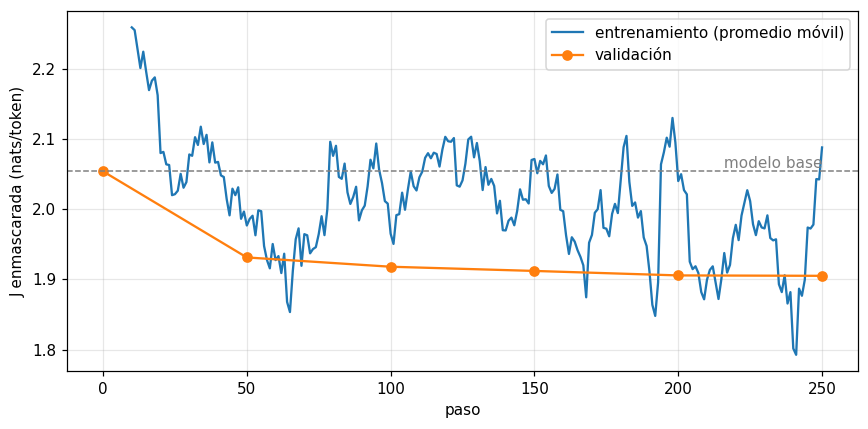

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
k = max(1, len(hist['train']) // 25)
suave = np.convolve(hist['train'], np.ones(k) / k, mode='valid')
ax.plot(hist['paso'][k - 1:], suave, label='entrenamiento (promedio móvil)')
ax.plot(hist['val_paso'], hist['val'], 'o-', label='validación')
ax.axhline(J_antes, color='gray', ls='--', lw=1)
ax.text(hist['paso'][-1], J_antes, ' modelo base', va='bottom', ha='right', color='gray')
ax.set_xlabel('paso'); ax.set_ylabel('J enmascarada (nats/token)'); ax.legend()
plt.tight_layout(); plt.show()

La NLL de validación baja sobre todo en los primeros pasos: el modelo aprende rápido el **formato** (cuándo empieza y cuándo termina una respuesta, el registro de Dolly) y mucho más despacio el contenido. 250 pasos y 2 millones de parámetros no le enseñan hechos nuevos; le enseñan a usar lo que ya sabía del preentrenamiento de otra forma.

## 8. Antes y después
Las mismas preguntas de la sección 3, con el mismo greedy.

In [15]:
despues = {}
for q in PREGUNTAS:
    despues[q] = responder(q)
    print('ANTES  ', end=''); mostrar(q, *antes[q])
    print('DESPUÉS', end=''); mostrar(q, *despues[q])
    print('-' * 100)

ANTES  ▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un número de protonos y eléctronos iguales. Un átomo es un
   elemento que tiene un número de protonos y eléctronos iguales. Un átomo es un elemento que tiene un
   número de protonos y eléctronos iguales. Un átomo es un elemento que tiene un número de protonos y
   eléctronos iguales. Un átomo es un elemento que tiene un número de protonos y eléctronos iguales. Un
   átomo es un elemento que tiene un
   se detuvo: NO, llegó al límite de tokens

DESPUÉS▶ ¿Qué es un átomo?
   Un átomo es un elemento que tiene un número de protones y un número de electrones.
   se detuvo: sí

----------------------------------------------------------------------------------------------------
ANTES  ▶ Dame tres ideas para ahorrar agua en casa.
   ¡Claro! Aquí tienes algunas ideas para ahorrar agua en casa: ⏎  ⏎ 1. **Utiliza el agua caliente**:
   Si tienes una cama o un baño, utiliza el agua caliente para lavar tu ropa. Esto reduce el consumo

Y una medida simple de lo que más cambió: en cuántas preguntas de validación el modelo **se detiene solo**. `sin_lora()` apaga $BA_r$ y deja el modelo base sin cargarlo otra vez.

In [16]:
N_PARO = 12 if dev == 'cuda' else 3
preguntas_val = [e['instruction'] for e in val.select(range(N_PARO))]
with sin_lora():
    paro_antes = [responder(q)[1] for q in preguntas_val]
paro_despues = [responder(q)[1] for q in preguntas_val]
print(f'se detiene solo, en {N_PARO} preguntas de validación: base {sum(paro_antes)}/{N_PARO} · '
      f'con LoRA {sum(paro_despues)}/{N_PARO}')
e = val[0]
print('\nUna pregunta de validación, con la respuesta de Dolly al lado:')
mostrar(e['instruction'], *responder(e['instruction']))
print('   Dolly:', textwrap.shorten(e['response'], 300))

se detiene solo, en 12 preguntas de validación: base 3/12 · con LoRA 8/12

Una pregunta de validación, con la respuesta de Dolly al lado:
▶ Dame una lista de los suplementos más consensuados que son eficaces para mantener la salud general
   1. Vitamina D ⏎ 2. Vitamina C ⏎ 3. Vitamina E ⏎ 4. Vitamina B ⏎ 5. Vitamina A ⏎ 6. Vitamina B12 ⏎ 7.
   Vitamina B6 ⏎ 8. Vitamina B1 ⏎ 9. Vitamina B2 ⏎ 10. Vitamina B3 ⏎ 11. Vitamina B5 ⏎ 12. Vitamina B11
   ⏎ 13. Vitamina B12 ⏎ 14. Vitamina B12 ⏎ 15. Vitamina B12 ⏎ 16. Vitamina B12
   se detuvo: NO, llegó al límite de tokens

   Dolly: 1) Vitamina D 2) Aceite de pescado Omega-3 3) Monohidrato de creatina 4) Multivitamínico *Descargo de responsabilidad: existen otros innumerables suplementos; sin embargo, décadas de investigación parecen haber formado un consenso sobre la eficacia de éstos


Después de entrenar, $W_0 + \frac{\alpha}{r}BA_r$ se puede fusionar en **una** matriz del mismo tamaño: el modelo ajustado cuesta lo mismo al generar que el base (diapositiva 66). El cambio es pequeño frente a $W_0$: el ajuste mueve poco los pesos.

In [17]:
with torch.no_grad():
    c = capas[0]
    x = torch.randn(4, c.base.in_features, device=dev)
    W = c.base.weight + c.escala * c.B @ c.A                  # W0 + B A_r: una matriz del mismo tamaño
    dif = (F.linear(x, W, c.base.bias) - c(x)).abs().max().item()
print(f'{c.base.weight.shape}: diferencia entre LoRA y la matriz fusionada {dif:.2e}')
print(f'norma de W0 {c.base.weight.norm():.1f} · norma del cambio (alpha/r) B A_r {(c.escala * c.B @ c.A).norm():.3f}')

torch.Size([896, 896]): diferencia entre LoRA y la matriz fusionada 7.63e-06
norma de W0 60.7 · norma del cambio (alpha/r) B A_r 0.483


In [18]:
torch.save({n: p.detach().cpu() for n, p in modelo.named_parameters() if p.requires_grad}, 'lora_dolly_es.pt')
json.dump({'modelo': MODELO, 'n_train': len(train), 'n_val': len(val), 'pasos': PASOS,
           'parametros': N_TOTAL, 'entrenables': N_LORA, 'segundos': SEGUNDOS, 'memoria_gb': MEMORIA,
           'J_antes': J_antes, 'J_despues': J_despues, 'hist': hist,
           'paro_antes': sum(paro_antes), 'paro_despues': sum(paro_despues), 'n_paro': N_PARO,
           'antes': {q: list(v) for q, v in antes.items()}, 'despues': {q: list(v) for q, v in despues.items()},
           'por_token': {'piezas': [tok.decode([i]) for i in ids_c], 'papel': papel_c, 'L': L_c}},
          open('resultados_sft.json', 'w'), ensure_ascii=False, indent=1)
print('guardado: lora_dolly_es.pt (', os.path.getsize('lora_dolly_es.pt') // 2**20, 'MB) y resultados_sft.json')

guardado: lora_dolly_es.pt ( 8 MB) y resultados_sft.json


## Tu turno · 15 minutos
1. **Sin la máscara.** En `J_enmascarada`, usa `att` en lugar de `m` (todos los tokens reales cuentan), vuelve a poner LoRA (corre desde la sección 6) y entrena. Compara la NLL de validación (con máscara) y las respuestas. ¿Empieza el modelo a escribir preguntas?
2. **El rango.** Prueba `r = 4` y `r = 64`. ¿Cuántos parámetros entrenables hay en cada caso? ¿Cambia la NLL de validación?
3. **Menos datos.** Entrena con `N_TRAIN = 200`. ¿Cuánto del cambio de la sección 8 se conserva?
4. **Con contexto.** Agrega a la plantilla un trozo `Contexto:` y usa también las preguntas con `context` (`closed_qa`, `summarization`). ¿Qué papel le darías a esos tokens en la máscara?

**Para pensar.** Aquí la respuesta "correcta" es la de Dolly. En el **ejercicio integrador** (notebook 6.6), el objetivo es otro: que un modelo que ya conversa responda **con un estilo**. ¿Bastará con pedírselo en el *prompt*?

In [19]:
# Tu turno

### Referencias
- Ouyang et al. (2022), *Training language models to follow instructions with human feedback*, NeurIPS (SFT y luego preferencias).
- Hu et al. (2021), *LoRA: Low-Rank Adaptation of Large Language Models*, ICLR 2022.
- Conover et al. (2023), *Free Dolly: Introducing the World's First Truly Open Instruction-Tuned LLM*, Databricks (el conjunto Dolly-15k).
- Qwen Team (2024), *Qwen2.5 Technical Report* (el modelo base).
- Amini et al., MIT 6.S191 (2025), Lab 3: *Fine-tune an LLM* (la estructura del ajuste con máscara y LoRA).